# AOL Scientific Computing

Nama: Nadya Angelie Lislie

NIM: [ID removed]

Kelas: LA06

## Peparation:

In [59]:
#Importing necessary libraries for this entire notebook
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.stats import linregress

In [60]:
#reading the file
data = pd.read_csv("aol_data.csv", header=0)
data.head()

,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,...,M135,M136,M137,M138,M139,M140,M141,M142,M143,M144
0,1863,1614,2570,1685,2101,1811,2457,2171,2134,2502,...,14917,15046,15556,15893,16388,16782,16716,17033,16896,17689


In [61]:
print(data.shape)

(1, 144)


The data shape shows that there are 144 data points. However, the question stated "You are given a set of data that consists of the monthly production of a certain type of bag they produced. The data span from January 2018 to December 2023". The number of months on that span is 72, which means that two data points are for one month.

In [62]:
#Agregating 2 data points for the range of 1 month
prod = data.iloc[0].values
production = [np.mean(prod[i:i + 2]) for i in range(0, len(prod), 2)]
month = np.arange(1, len(production) + 1)

print(month)
print("=========================================")
print(production)

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72]
[1738.5, 2127.5, 1956.0, 2314.0, 2318.0, 2378.5, 2285.5, 2238.5, 2245.0, 2703.0, 2980.5, 2804.5, 3041.0, 2752.0, 3062.0, 3195.5, 3290.0, 3566.0, 3426.5, 3601.0, 3304.0, 3806.5, 3595.0, 4039.5, 4319.0, 4628.5, 4564.5, 4956.0, 4666.5, 5093.0, 4906.5, 5209.0, 5376.0, 5487.0, 5722.0, 6111.5, 6315.5, 6231.5, 6387.5, 6614.0, 6758.5, 6589.0, 7209.0, 7692.5, 7985.5, 8101.5, 8052.0, 8650.5, 8684.5, 8901.5, 9156.5, 9118.0, 9848.5, 10007.0, 10492.0, 10355.5, 10810.5, 11240.0, 11986.0, 11970.0, 12294.5, 12983.0, 13348.0, 13447.0, 13726.0, 14046.5, 15104.5, 14981.5, 15724.5, 16585.0, 16874.5, 17292.5]


## Number 1:

Question: You must find the trend on the bag’s production from the data. You must provide a mathematical model that can explain the production’s trend accurately. Since your supervisor want an accurate model, you must avoid any linear approach to build the trend model. 

In [63]:
#This is the function to count error of model
def error(y, yPred):
    error_val = y - yPred
    mae = np.mean(np.abs(error_val))
    mse = np.mean((error_val) ** 2)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((yPred - y) / y)) * 100

    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"Mean Percentage Error (MAPE): {mape:.4f}")

In [64]:
#Because I am avoiding linear approach, I am using polynomial regression
#I am now making 2nd degree polynomial regression and are printing the error
x = np.array(month)
y = np.array(production)

A = np.vstack([x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred = inv[0]*x*x+inv[1]*x+inv[2]

print("Degree 2:")
print(f"Equation:\n y = {inv[0]:.4f}*x^2 {inv[1]:.4f}*x + {inv[2]:.4f}")
error(y, yPred)

Degree 2:
Equation:
 y = 2.8216*x^2 -4.6065*x + 2348.2757
Mean Absolute Error (MAE): 238.9612
Mean Squared Error (MSE): 86683.3280
Root Mean Squared Error (RMSE): 294.4203
Mean Percentage Error (MAPE): 4.6978


From the output above, we see that the error is still quite big. Let's test for other degrees and see if other degree has less error and is more suitable for this data.

In [65]:
#Now, I want to see the error of 3rd-6th degree polinomial regression.
print("Degree 3:")
x = np.array(month)
y = np.array(production)

A = np.vstack([x**3, x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred3 = inv[0]*x*x*x+inv[1]*x*x+inv[2]*x+inv[3]
print(f"Equation:\n y = {inv[0]:.4f}*x^3 + {inv[1]:.4f}*x^2 +{inv[2]:.4f}*x + {inv[3]:.4f}")
print("\n")
error(y, yPred3)

print("\n------------------------------------------------------------")

print("Degree 4:")
x = np.array(month)
y = np.array(production)

A = np.vstack([x**4, x**3, x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred4 = inv[0]*x*x*x*x+inv[1]*x*x*x+inv[2]*x*x+inv[3]*x+inv[4]
print(f"Equation:\n y = {inv[0]:.4f}*x^4 + {inv[1]:.4f}*x^3 +{inv[2]:.4f}*x^2 + {inv[3]:.4f}*x + {inv[4]:.4f}")
print("\n")
error(y, yPred4)

print("\n-----------------------------------------------------------")

print("Degree 5:")
x = np.array(month)
y = np.array(production)

A = np.vstack([x**5, x**4, x**3, x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred5 = inv[0]*x*x*x*x*x+inv[1]*x*x*x*x+inv[2]*x*x*x+inv[3]*x*x+inv[4]*x+inv[5]
print(f"Equation:\n y = {inv[0]:.4f}*x^5 + {inv[1]:.4f}*x^4 + {inv[2]:.4f}*x^3 + {inv[3]:.4f}*x^2 + {inv[4]:.4f}*x + {inv[5]:.4f}")
print("\n")
error(y, yPred5)

print("\n-----------------------------------------------------------")

print("Degree 6:")
x = np.array(month)
y = np.array(production)

A = np.vstack([x**6, x**5, x**4, x**3, x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred6 = inv[0]*x*x*x*x*x*x+inv[1]*x*x*x*x*x+inv[2]*x*x*x*x+inv[3]*x*x*x+inv[4]*x*x+inv[5]*x+inv[6]
print(f"Equation:\n y = {inv[0]:.4f}*x^6 + {inv[1]:.4f}*x^5 + {inv[2]:.4f}*x^4 + {inv[3]:.4f}*x^3 + {inv[4]:.4f}*x^2 +{inv[5]:.4f}*x + {inv[6]:.4f}")
print("\n")
error(y, yPred6)

Degree 3:
Equation:
 y = 0.0311*x^3 + -0.5818*x^2 +95.4593*x + 1718.6491


Mean Absolute Error (MAE): 156.5894
Mean Squared Error (MSE): 38747.7706
Root Mean Squared Error (RMSE): 196.8445
Mean Percentage Error (MAPE): 3.0607

------------------------------------------------------------
Degree 4:
Equation:
 y = 0.0004*x^4 + -0.0343*x^3 +2.5025*x^2 + 44.6121*x + 1915.7393


Mean Absolute Error (MAE): 150.3719
Mean Squared Error (MSE): 35479.0873
Root Mean Squared Error (RMSE): 188.3589
Mean Percentage Error (MAPE): 3.0316

-----------------------------------------------------------
Degree 5:
Equation:
 y = 0.0000*x^5 + -0.0011*x^4 + 0.0666*x^3 + -0.2913*x^2 + 74.5689*x + 1835.7966


Mean Absolute Error (MAE): 148.4434
Mean Squared Error (MSE): 35096.2328
Root Mean Squared Error (RMSE): 187.3399
Mean Percentage Error (MAPE): 2.9722

-----------------------------------------------------------
Degree 6:
Equation:
 y = -0.0000*x^6 + 0.0000*x^5 + -0.0011*x^4 + 0.0636*x^3 + -0.1886*x^2 +73.54

From the result above, the errors keep on decreasing as we add more degree to the polynomial regression model. But, it increases again at 6th degree. 

**So, the most suitable degree is degree of 5.**

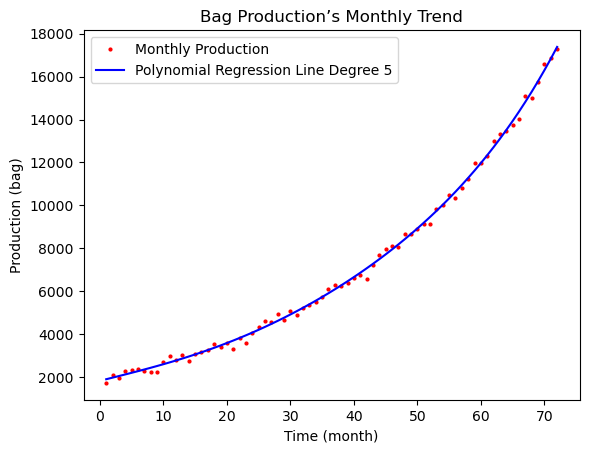

In [66]:
#So, I will be using 5th degree of polynomial regression.
#I also print the plot of my model
x = np.array(month)
y = np.array(production)

A = np.vstack([x**5, x**4, x**3, x**2, x*1, np.ones(len(x))]).T
inv = np.linalg.inv(np.dot(A.T, A))
inv = np.dot(inv, A.T)
inv = np.dot(inv, y)

yPred5 = inv[0]*x*x*x*x*x+inv[1]*x*x*x*x+inv[2]*x*x*x+inv[3]*x*x+inv[4]*x+inv[5]

plt.plot(x,y,"ro", markersize = 2)
plt.plot(x,yPred5,"b-")
plt.legend(["Monthly Production","Polynomial Regression Line Degree 5"])
plt.title("Bag Production’s Monthly Trend")
plt.xlabel("Time (month)")
plt.ylabel("Production (bag)")
plt.show()

=================================================================

## Number 2:

Since you’ll need to process the data using a computer program, you’ll need to convert the mathematical model from problem #1 to its numerical form (approximation). This is done so that the mathematical model can be calculated by the program easily. Since accuracy is still important, make sure that your conversion is accurate as possible. Provide an explanation to your supervisor about the accuracy of your conversion.

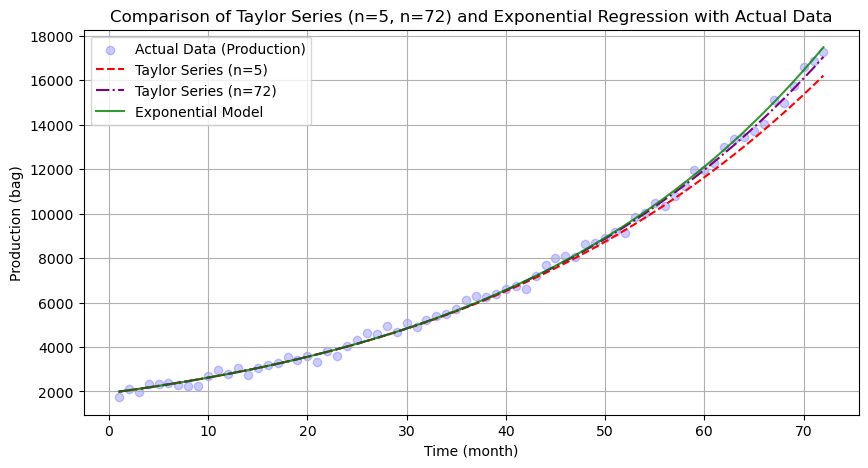

Error of Taylor Series (5 Term):


TypeError: unsupported operand type(s) for -: 'list' and 'list'

In [67]:
#I will make the taylor series model and compare it to the actual data and its exponential regression line

#First, I make my exponential model
ln_y = np.log(production)
slope, intercept, _, _, _ = linregress(months, ln_y)
a = np.exp(intercept)
b = slope
exp_values = a * np.exp(b * months)

#Now, I make the taylor series function
def taylor_series(x, n_terms):
    result = 0
    for n in range(n_terms):
        term = (a * (b ** n) * (x ** n)) / math.factorial(n)
        result += term
    return result

#I want to also compare the taylor series when I use small term (5) and large term (72, which is the same as our current number of months)
n_terms_5 = 5
n_terms_72 = 72
taylor_values_5 = [taylor_series(x, n_terms_5) for x in months]
taylor_values_72 = [taylor_series(x, n_terms_72) for x in months]

plt.figure(figsize=(10, 5))
plt.scatter(months, production, label="Actual Data (Production)", color="blue", alpha=0.2)
plt.plot(months, taylor_values_5, label=f"Taylor Series (n={n_terms_5})", color="red", linestyle="--")
plt.plot(months, taylor_values_72, label=f"Taylor Series (n={n_terms_72})", color="purple", linestyle="-.")
plt.plot(months, exp_values, label="Exponential Model", color="green", linestyle="-", alpha=0.8)
plt.xlabel("Time (month)")
plt.ylabel("Production (bag)")
plt.title("Comparison of Taylor Series (n=5, n=72) and Exponential Regression with Actual Data")
plt.legend()
plt.grid(True)
plt.show()

#Here, I am comparing the error of the three models
print("Error of Taylor Series (5 Term):")
error(production, taylor_values_5)
print("\n-----------------------------------------------------------")
print("Error of Taylor Series (72 Term):")
error(production, taylor_values_72)
print("\n-----------------------------------------------------------")
print("Error of Exponential Model:")
error(production, exp_values)

The Taylor Series with 5 terms (small number) shows higher error compared to the other models, with a Mean Absolute Error (MAE) of 268.65 and a Root Mean Squared Error (RMSE) of 376.46, indicating that it doesn't fit the data very well. In contrast, using 72 terms (a lot bigger number) in the Taylor Series significantly reduces the error, bringing the MAE down to 162.05 and the RMSE to 206.66, showing a much better fit to the data. The Exponential Model also performs well, with an MAE of 164.49 and RMSE of 209.00, which is similar to the 72-term Taylor Series, indicating that both models provide similar accuracy in predicting the production values.

Moreover, in the graph we observe that the actual production data (blue scatter points) is compared with the predictions from both models. The 5-term Taylor Series (red dashed line) does not follow the actual data closely, while the 72-term Taylor Series (purple dash-dotted line) and the Exponential Model (green solid line) both closely match the actual values. This confirms that the 72-term Taylor Series and the Exponential Model are effective in predicting the production values, while the 5-term Taylor Series has higher errors and doesn't fit as well.

## Number 3:

The warehouse was designed to be able to store a maximum of 25,000 (twenty five thousands) bags at each month. Your supervisor asked you to provide a prediction when do EGIER need to build a new warehouse based on the trend that you have acquired in problem #2. To build a new warehouse, it is predicted that they need at least 13 months. So provide the time when EGIER need to start building their new warehouse. (Hint: this can be approached as a root of equation problem).

In [68]:
#I take the f(x) from Degree 5 polynomial that I made before 
#- 25000 (our target)
def f(x):
    return 0.0000*x**5 -0.0011*x**4 + 0.0666*x**3 -0.2913*x**2 + 74.5689*x + 1835.7966 - 25000

def g(x):
    return 0.0000*x**4 -0.0044*x**3 + 0.1998*x**2 -0.5826*x + 74.5689

In [69]:
#I am creating the newton raphson function
def newton_raphson(x0, tol = 0.01, iter = 15):
    for i in range(iter):
        x1 = x0 - f(x0) / g(x0)
        if(np.abs(f(x1)) < tol):
            print(f'Root: {x1}')
            return
        x0 = x1
    print('Not converged')

In [70]:
#Let's count the root if my initial condition is week 80
newton_raphson(90)

Not converged


I have tried a lot of different initial condition but the root is not converged so, I would like to try the bisection of this model as shown below:

In [71]:
def bisection(a,b, tol = 0.001, iter = 50):
    if(np.sign(f(a)) == np.sign (f(b))):
        print('Invalid points')
        return
    
    for i in range(iter):
        c = (a+b)/2
        if(np.abs(f(c)) < tol):
            print(f'Root: {c}')
            return
        elif(np.sign(f(c)) == np.sign(f(a))):
            a = c
        elif(np.sign(f(c)) == np.sign(f(b))):
            b = c
    print('Not converged')
    return

In [72]:
bisection(70,99)

Invalid points


To find the a and b for bisection, I should search for the valid points that would result in different signs.

In [73]:
#This is the loop to see the points where the result differs (+ and -)
for x in range(50, 150):
    print(f"x: {x}, f(x): {f(x)}")

x: 50, f(x): -18714.0084
x: 51, f(x): -18726.0253
x: 52, f(x): -18752.580599999998
x: 53, f(x): -18794.634299999998
x: 54, f(x): -18853.1728
x: 55, f(x): -18929.208899999998
x: 56, f(x): -19023.7818
x: 57, f(x): -19137.9571
x: 58, f(x): -19272.826800000003
x: 59, f(x): -19429.5093
x: 60, f(x): -19609.1494
x: 61, f(x): -19812.918299999998
x: 62, f(x): -20042.0136
x: 63, f(x): -20297.6593
x: 64, f(x): -20581.105799999998
x: 65, f(x): -20893.6299
x: 66, f(x): -21236.534799999998
x: 67, f(x): -21611.150100000003
x: 68, f(x): -22018.8318
x: 69, f(x): -22460.9623
x: 70, f(x): -22938.950399999998
x: 71, f(x): -23454.2313
x: 72, f(x): -24008.2666
x: 73, f(x): -24602.5443
x: 74, f(x): -25238.578799999996
x: 75, f(x): -25917.910899999995
x: 76, f(x): -26642.1078
x: 77, f(x): -27412.763100000004
x: 78, f(x): -28231.4968
x: 79, f(x): -29099.955300000005
x: 80, f(x): -30019.811399999995
x: 81, f(x): -30992.764300000003
x: 82, f(x): -32020.539600000004
x: 83, f(x): -33104.889299999995
x: 84, f(x): -

The results above are all in negative signs while the range is already big. This shows that the 5th degree might not work (overfit and there won't be any valid points) and I should decrease the degree, so I am trying 4th degree now:

In [74]:
def f(x):
    return 0.0004*x**4 + -0.0343*x**3 + 2.5025*x**2 + 44.6121*x 
    + 1915.7393 - 25000

def g(x):
    return 0.0008*x**3 + -0.1029*x**2 + 5.005*x + 44.6121

In [75]:
for x in range(50, 150):
    print(f"x: {x}, f(x): {f(x)}")

x: 50, f(x): 6699.355
x: 51, f(x): 6940.3706999999995
x: 52, f(x): 7188.381200000002
x: 53, f(x): 7443.6751
x: 54, f(x): 7706.5506
x: 55, f(x): 7977.315500000001
x: 56, f(x): 8256.2872
x: 57, f(x): 8543.7927
x: 58, f(x): 8840.1686
x: 59, f(x): 9145.7611
x: 60, f(x): 9460.926
x: 61, f(x): 9786.0287
x: 62, f(x): 10121.444200000002
x: 63, f(x): 10467.557100000002
x: 64, f(x): 10824.761600000002
x: 65, f(x): 11193.461500000001
x: 66, f(x): 11574.070200000002
x: 67, f(x): 11967.010699999999
x: 68, f(x): 12372.7156
x: 69, f(x): 12791.627100000002
x: 70, f(x): 13224.197
x: 71, f(x): 13670.886700000001
x: 72, f(x): 14132.1672
x: 73, f(x): 14608.519100000001
x: 74, f(x): 15100.4326
x: 75, f(x): 15608.407500000001
x: 76, f(x): 16132.953200000002
x: 77, f(x): 16674.5887
x: 78, f(x): 17233.8426
x: 79, f(x): 17811.2531
x: 80, f(x): 18407.368000000002
x: 81, f(x): 19022.7447
x: 82, f(x): 19657.950200000003
x: 83, f(x): 20313.561100000003
x: 84, f(x): 20990.1636
x: 85, f(x): 21688.3535
x: 86, f(x): 2

The results above show a change in sign. So, the root will be present using the 4th degree polynomial regression and in the range of at least 86 to 87. For instance, I use the range 80 to 150 like shown below:

In [76]:
bisection(80,150)

Invalid points


The root is found at 86.910. Let's crosscheck with newton raphson method

In [77]:
newton_raphson(86.91022783517838)

Root: -14.472081556548607


The same root is found with newton raphson method. This means that around week 86 to 87 (February to March 2025), the bag production will exceed the warehouse capacity of 25000. To build a new warehouse, it is predicted that they will need at least 13 months. So, it is safe to say that EGIER needs to start building their new warehouse in January 2024.